---
title: "The Hydrogen Atom and 3D Problems — Level 2"
short_title: "05 Hydrogen & 3D Problems"
numbering:
  heading_2: true
  equation: true
---

# The Hydrogen Atom and 3D Problems

:::{seealso} Math for this topic
- [Q-M2: Series solutions, Hermite and Laguerre functions](../math/02-series-solutions-special-functions.ipynb)
- [Q-M4: Rotations, angular momentum algebra and spherical harmonics](../math/04-rotations-spherical-harmonics.ipynb)
- [E-M2: Separation of variables and orthogonal functions](../../level2-em-book/math/02-separation-of-variables.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 36 | Bohr-model energies, quantum numbers |
| **2** | **Griffiths QM, ch. 4** | **Separation of variables in spherical coordinates, the radial equation, spherical harmonics** |
| 3 | Sakurai, ch. 3 | Algebraic solution via SO(4); the Coulomb problem with angular-momentum techniques |

The new skill at this level: separating the three-dimensional Schrödinger equation into an angular part (solved once for all central potentials) and a one-dimensional radial problem

Math for this topic: Q-M2 (Laguerre functions, series solutions), Q-M4 (spherical harmonics) and E&M E-M2 (separation of variables).
:::

Workbook example ladder: Bohr energy levels → radial wave functions and their expectation values → the extra degeneracy from hidden SO(4) symmetry. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Separating a Central Potential

In three dimensions the Schrödinger equation is $-\frac{\hbar^2}{2m}\nabla^2\psi + V\psi = E\psi$. When $V$ depends only on $r$, write the Laplacian in spherical coordinates and try $\psi = R(r)Y(\theta, \phi)$. The angular part of $\nabla^2$ is $-\hat L^2/\hbar^2r^2$ (Q-M4), so the angular equation is $\hat L^2Y = \hbar^2\ell(\ell+1)Y$, solved once and for all by the spherical harmonics $Y_\ell^m$.

What remains is one-dimensional. With $u(r) = rR(r)$,

$$
-\frac{\hbar^2}{2m}\frac{d^2u}{dr^2} + \left[V(r) + \frac{\hbar^2}{2m}\frac{\ell(\ell+1)}{r^2}\right]u = Eu ,
$$ (eq-radial)

the **radial equation**. It looks like a 1D problem on $r > 0$ with an **effective potential** that adds a centrifugal barrier $\hbar^2\ell(\ell+1)/2mr^2$ (the quantum version of $L^2/2mr^2$ in mechanics' orbits). The boundary condition is $u(0) = 0$, and normalization is $\int_0^\infty|u|^2dr = 1$.

## The Hydrogen Atom

For the Coulomb potential $V = -e^2/4\pi\epsilon_0r$, Q-M2 solves {eq}`eq-radial`: peel off $r^{\ell+1}$ near the origin and $e^{-\kappa r}$ far away, and require the remaining power series to terminate. Termination forces

$$
E_n = -\frac{m}{2\hbar^2}\left(\frac{e^2}{4\pi\epsilon_0}\right)^2\frac{1}{n^2} = -\frac{13.6\text{ eV}}{n^2},\qquad n = 1, 2, 3, \ldots
$$ (eq-hydrogen-energies)

with $\ell = 0, 1, \ldots, n - 1$ and $m = -\ell, \ldots, \ell$. The length scale is the **Bohr radius** $a = 4\pi\epsilon_0\hbar^2/me^2 = 0.0529$ nm, and the wave functions are

$$
\psi_{n\ell m} = R_{n\ell}(r)\,Y_\ell^m(\theta, \phi),\qquad
R_{n\ell}\propto\left(\frac{2r}{na}\right)^\ell e^{-r/na}\,L^{2\ell+1}_{n-\ell-1}\!\left(\frac{2r}{na}\right) .
$$ (eq-hydrogen-psi)

The ground state is $\psi_{100} = e^{-r/a}/\sqrt{\pi a^3}$.

**Degeneracy.** The energy depends only on $n$. For each $n$ there are $\sum_{\ell=0}^{n-1}(2\ell + 1) = n^2$ states (doubled to $2n^2$ with spin). The degeneracy in $m$ is expected for any central potential (rotational symmetry). The degeneracy in $\ell$ is special to $1/r$, and comes from a hidden conserved quantity, the quantum version of the Laplace–Runge–Lenz vector that keeps Kepler orbits closed (mechanics topic 7). At Level 3 it enlarges the symmetry from rotations to SO(4).

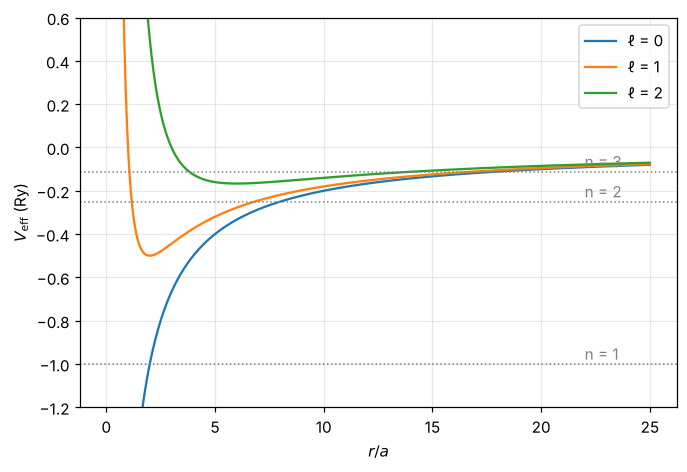

In [2]:
#| label: fig-effective-potential
#| caption: "Effective radial potentials for hydrogen (in units of the Rydberg energy 13.6 eV, r in Bohr radii) for ℓ = 0, 1, 2, with the n = 1, 2, 3 energy levels. The centrifugal barrier pushes higher-ℓ states away from the nucleus; the ℓ = 0 states alone feel the full Coulomb attraction at small r."
r = np.linspace(0.05, 25, 800)
fig, ax = plt.subplots()
for l, col in [(0, "tab:blue"), (1, "tab:orange"), (2, "tab:green")]:
    ax.plot(r, -2 / r + l * (l + 1) / r**2, color=col, label=f"ℓ = {l}")
for n in [1, 2, 3]:
    ax.axhline(-1 / n**2, color="gray", ls=":", lw=1); ax.text(22, -1 / n**2 + 0.02, f"n = {n}", color="gray")
ax.set_ylim(-1.2, 0.6); ax.set_xlabel("$r/a$"); ax.set_ylabel("$V_{\\rm eff}$ (Ry)"); ax.legend(); plt.show()

In [3]:
# Check that R_21 solves the radial equation with E = E_2, in units hbar = m = e^2/(4 pi eps0) = 1 (so a = 1, E_n = -1/(2n^2))
rr = sp.symbols("r", positive=True)
def R(n, l):
    rho = 2 * rr / n
    return rho**l * sp.exp(-rho / 2) * sp.assoc_laguerre(n - l - 1, 2 * l + 1, rho)
for n, l in [(1, 0), (2, 1), (3, 1), (3, 2)]:
    u = rr * R(n, l)
    lhs = -sp.diff(u, rr, 2) / 2 + (-1 / rr + l * (l + 1) / (2 * rr**2)) * u
    ok = sp.simplify(lhs - sp.Rational(-1, 2 * n**2) * u) == 0
    N = sp.integrate(u**2, (rr, 0, sp.oo))
    rmean = sp.simplify(sp.integrate(rr * u**2, (rr, 0, sp.oo)) / N)
    display(Math(rf"(n,\ell) = ({n},{l}):\quad \text{{radial equation }}" + (r"\checkmark" if ok else r"\times") + rf",\quad \langle r\rangle = {sp.latex(rmean)}\,a"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The $\langle r\rangle$ values match the general formula $\langle r\rangle = \tfrac a2\left[3n^2 - \ell(\ell+1)\right]$: the atom grows like $n^2$, and for fixed $n$ the high-$\ell$ states (closest to circular orbits) are slightly smaller on average.

::::{prf:example} Level 1 rung: the Balmer lines
:label: ex-balmer

Find the wavelengths of the first three lines of the Balmer series ($n\to2$) and say which are visible.

:::{dropdown} Solution
A photon from $n_i\to n_f$ carries $13.6\text{ eV}(1/n_f^2 - 1/n_i^2)$, so

$$
\frac1\lambda = R_\infty\left(\frac{1}{n_f^2} - \frac{1}{n_i^2}\right),\qquad R_\infty = 1.097\times10^7\ \text{m}^{-1} .
$$

$3\to2$: 656 nm (red, H-α); $4\to2$: 486 nm (blue-green, H-β); $5\to2$: 434 nm (violet, H-γ). All three are visible; H-α gives emission nebulae their pink-red color. (Using the reduced mass of the electron–proton pair shifts these by 0.05%.)
:::
::::

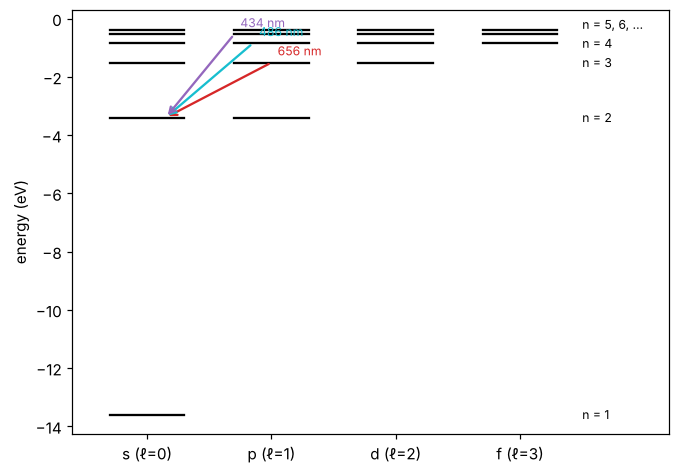

In [4]:
#| label: fig-hydrogen-levels
#| caption: "Hydrogen energy levels up to n = 6, drawn by ℓ (s, p, d, f columns), with the first three Balmer transitions to n = 2. All ℓ for a given n share the same energy in this model; fine structure (topic 8) splits them slightly. Allowed transitions change ℓ by ±1 (topic 10)."
fig, ax = plt.subplots(figsize=(7, 5))
for n in range(1, 7):
    E = -13.6 / n**2
    for l in range(min(n, 4)):
        ax.plot([l - 0.3, l + 0.3], [E, E], color="k", lw=1.5)
    if n <= 4: ax.text(3.5, E, f"n = {n}", va="center", fontsize=8)
for ni, col, lab in [(3, "tab:red", "656 nm"), (4, "tab:cyan", "486 nm"), (5, "tab:purple", "434 nm")]:
    ax.annotate("", xy=(0.15, -3.4), xytext=(1.0 - 0.15 * (ni - 3), -13.6 / ni**2),
                arrowprops=dict(arrowstyle="->", color=col, lw=1.5))
    ax.text(1.05 - 0.15 * (ni - 3), -13.6 / ni**2 + 0.25, lab, color=col, fontsize=8)
ax.text(3.5, -0.2, "n = 5, 6, ...", va="center", fontsize=8)
ax.set_xticks(range(4)); ax.set_xticklabels(["s (ℓ=0)", "p (ℓ=1)", "d (ℓ=2)", "f (ℓ=3)"])
ax.set_xlim(-0.6, 4.2); ax.set_ylabel("energy (eV)"); ax.grid(False); plt.show()

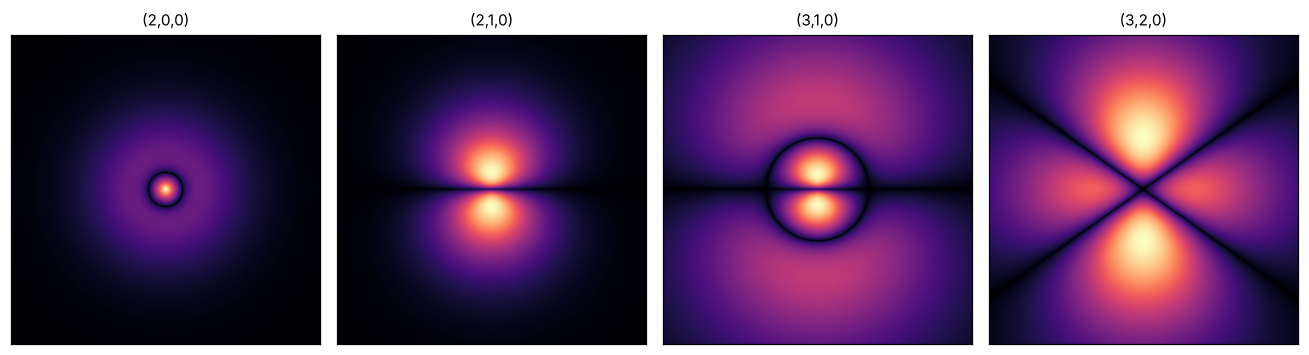

In [5]:
#| label: fig-orbital-densities
#| caption: "Probability density |ψ_nℓm|² in the x–z plane (z vertical) for (n, ℓ, m) = (2, 0, 0), (2, 1, 0), (3, 1, 0) and (3, 2, 0), each on its own color scale (color ∝ density^0.3, so faint outer lobes show). Radial nodes are circles, angular nodes are cones (lines here); the total number of nodes is n − 1."
from scipy.special import eval_genlaguerre, sph_harm_y, factorial
def psi_nlm(n, l, m, X, Z):
    r = np.sqrt(X**2 + Z**2); th = np.arctan2(np.abs(X), Z)
    rho = 2 * r / n
    norm = np.sqrt((2 / n)**3 * factorial(n - l - 1) / (2 * n * factorial(n + l)))
    Rr = norm * rho**l * np.exp(-rho / 2) * eval_genlaguerre(n - l - 1, 2 * l + 1, rho)
    return Rr * sph_harm_y(l, m, th, 0.0)
g = np.linspace(-18, 18, 300); X, Z = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (n, l, m) in zip(axes, [(2, 0, 0), (2, 1, 0), (3, 1, 0), (3, 2, 0)]):
    ax.imshow((np.abs(psi_nlm(n, l, m, X, Z))**2)**0.3, extent=[g[0], g[-1], g[0], g[-1]], origin="lower", cmap="magma")
    ax.set_title(f"({n},{l},{m})", fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

## Solving the Radial Equation Numerically

For potentials without an exact solution, {eq}`eq-radial` is a 1D eigenvalue problem. Discretizing $u''$ with finite differences turns it into a matrix eigenvalue problem (Q-M3). Testing on hydrogen first is the standard check.

In [6]:
# Finite differences on 0 < r < 200 a, units: hbar = m = e^2/4pi eps0 = 1, energies in hartree (E_n = -1/2n^2)
N = 8000; rmax = 200.0
rg = np.linspace(rmax / N, rmax, N); h_ = rg[1] - rg[0]
def levels(l, k=4):
    diag = 1 / h_**2 - 1 / rg + l * (l + 1) / (2 * rg**2)
    off = -0.5 / h_**2 * np.ones(N - 1)
    from scipy.linalg import eigh_tridiagonal
    return eigh_tridiagonal(diag, off, select="i", select_range=(0, k - 1))[0]
for l in [0, 1, 2]:
    E = levels(l)
    exact = [-0.5 / n**2 for n in range(l + 1, l + 5)]
    display(Math(rf"\ell = {l}:\quad E_{{\rm num}} = " + ",\\ ".join(f"{e:.5f}" for e in E) + r"\qquad E_{\rm exact} = " + ",\\ ".join(f"{e:.5f}" for e in exact)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Another 3D Problem: the Spherical Well

For a particle in a spherical box of radius $a$ ($V = 0$ inside, infinite outside), the radial solutions are spherical Bessel functions (Q-M5), $R = j_\ell(kr)$, and $R(a) = 0$ requires $ka = \beta_{n\ell}$, the $n$th zero of $j_\ell$:

$$
E_{n\ell} = \frac{\hbar^2\beta_{n\ell}^2}{2ma^2} .
$$ (eq-spherical-well)

For $\ell = 0$, $j_0 = \sin x/x$ and $\beta_{n0} = n\pi$, exactly the 1D well. Higher $\ell$ have no closed form. Unlike hydrogen, there is no degeneracy across $\ell$: each $(n, \ell)$ level is just $(2\ell+1)$-fold degenerate. The ordering of these levels (1s, 1p, 1d, 2s, ...) is the starting point of the nuclear shell model.

In [7]:
from scipy.special import spherical_jn
def zeros_jl(l, count=3):
    xs = np.linspace(0.5, 20, 4000); f = spherical_jn(l, xs)
    idx = np.where(np.sign(f[:-1]) != np.sign(f[1:]))[0][:count]
    return [brentq(lambda x: spherical_jn(l, x), xs[i], xs[i + 1]) for i in idx]
rows = sorted([(z**2, n + 1, l) for l in range(4) for n, z in enumerate(zeros_jl(l))])[:8]
lab = "spdf"
display(Math(r"\text{lowest levels } (2ma^2E/\hbar^2):\ " + ",\\ ".join(f"{n}{lab[l]}\\,{e:.2f}" for e, n, l in rows)))

<IPython.core.display.Math object>

### Exercises

1. Show that $\psi_{100}$ is normalized and find $\langle r\rangle$ and the most probable $r$. Why do they differ?
2. For the ground state of hydrogen, find $\langle V\rangle$ and $\langle T\rangle$ and check that $\langle T\rangle = -E_1$, $\langle V\rangle = 2E_1$ (the virial theorem for $1/r$).
3. What is the probability that the ground-state electron is found inside the proton ($r < 1$ fm)?
4. Count the states with $n = 3$, listing $(\ell, m)$, and check $n^2 = 9$.
5. Find the wavelength of the Lyman-α line ($2\to1$). In which part of the spectrum is it?

:::{dropdown} Hints
1. $\int_0^\infty r^ne^{-2r/a}dr = n!(a/2)^{n+1}$; the most probable $r$ maximizes $r^2|\psi|^2$.
2. $\langle1/r\rangle = 1/a$ for the ground state.
3. For $r\ll a$, $|\psi|^2\approx1/\pi a^3$; multiply by the proton's volume.
4. $\ell = 0, 1, 2$.
5. $1/\lambda = R_\infty(1 - 1/4)$.
:::

:::{dropdown} Answers
1. $\langle r\rangle = \tfrac32a$; most probable $r = a$. The density $r^2e^{-2r/a}$ has a long tail that pulls the mean out.
2. $\langle V\rangle = -e^2/4\pi\epsilon_0a = -27.2$ eV $= 2E_1$; $\langle T\rangle = 13.6$ eV $= -E_1$.
3. $P\approx\tfrac43(r_p/a)^3 = \tfrac43(10^{-15}/5.29\times10^{-11})^3\approx9\times10^{-15}$. Small but not zero, which matters for the hyperfine structure and for electron capture in heavier nuclei.
4. $\ell = 0$: 1; $\ell = 1$: 3; $\ell = 2$: 5; total 9.
5. $\lambda = 121.6$ nm, in the ultraviolet. It is absorbed by Earth's atmosphere, so it is observed from space.
:::

## Summary

- Central potentials separate: $Y_\ell^m$ for the angles (any $V(r)$), and a 1D radial equation for $u = rR$ with a centrifugal term.
- Hydrogen: $E_n = -13.6\text{ eV}/n^2$, $\ell < n$, degeneracy $n^2$; wave functions are Laguerre polynomials times exponentials times $Y_\ell^m$. Scale $a = 0.0529$ nm, $\langle r\rangle\propto n^2$.
- The $\ell$-degeneracy is special to $1/r$ (hidden symmetry); other potentials, like the spherical well, split levels by $\ell$.
- Finite differences turn the radial equation into a matrix eigenproblem; check on hydrogen first.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.